# Day 33 — Business Insights
Retail Sales & Customer Performance Analysis

Objective: translate observations into evidence-based management implications. An observation states a number; an insight explains its business relevance. The institute requires at least 10 findings in Finding / Evidence / Business Impact format.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image
p = Path('.')
df = pd.read_csv(p/'transformed_retail_sales.csv', parse_dates=['Order_Date'])
assert df.Order_ID.is_unique and df.Sales.notna().all()
assert (df.Sales == df.Quantity * df.Unit_Price).all()
revenue = df.Sales.sum(); orders = df.Order_ID.nunique(); customers = df.Customer_Name.nunique()
customer = df.groupby('Customer_Name').agg(Revenue=('Sales','sum'), Orders=('Order_ID','nunique')).sort_values('Revenue',ascending=False)
product = df.groupby('Product').agg(Revenue=('Sales','sum'), Units=('Quantity','sum'), Orders=('Order_ID','nunique')).sort_values('Revenue',ascending=False)
category = df.groupby('Category').Sales.sum().sort_values(ascending=False)
city = df.groupby('City').Sales.sum().sort_values(ascending=False)
monthly = df.groupby(df.Order_Date.dt.to_period('M')).Sales.sum()
segment = df.groupby('Customer_Segment').agg(Customers=('Customer_Name','nunique'),Revenue=('Sales','sum'))
assert df.groupby('Customer_Name').Customer_Segment.nunique().max()==1
for x in [customer.Revenue,product.Revenue,category,city,monthly,segment.Revenue]: assert x.sum()==revenue
print('Rows, columns:',df.shape, '| Revenue:',revenue,'| Orders:',orders,'| Observed customers:',customers)
for x in [customer,product,category,city,monthly,segment]: display(x)


Rows, columns: (30, 27) | Revenue: 81870 | Orders: 30 | Observed customers: 6


,Revenue,Orders
Customer_Name,,
Priya,17780,5
Asha,14240,5
Vikram,13350,5
Rahul,13350,5
Arjun,12450,5
Neha,10700,5


,Revenue,Units,Orders
Product,,,
Headphones,36000,24,7
Lamp,24200,22,7
T-Shirt,14950,23,8
Rice,6720,21,8


Category
Electronics    36000
Home           24200
Clothing       14950
Grocery         6720
Name: Sales, dtype: int64

City
Pune      33140
Nashik    24680
Nagpur    14970
Mumbai     9080
Name: Sales, dtype: int64

Order_Date
2026-10    81870
Freq: M, Name: Sales, dtype: int64

,Customers,Revenue
Customer_Segment,,
High Value,1,17780
Medium Value,5,64090


## Reconciliation with prior work
Compare the recomputed totals against saved Day 29 KPI and Day 31–32 dashboard validation exports. Day 25–27 use the same transformed dataset; the earlier summaries are retained for reference. Native PBIX interactions are not independently inspected.

In [2]:
v=Path('prior_validation')
kpi=pd.read_csv(next(v.glob('Day29*/KPI_Summary.csv'))).set_index('KPI')
assert float(kpi.loc['Total Revenue','Value'])==revenue
for day,filename,key,measure,expected in [(31,'Category_Validation.csv','Category','Sales',category),(31,'Region_City_Validation.csv','City','Sales',city),(31,'Product_Validation.csv','Product_Name','Sales',product.Revenue),(32,'Customer_Validation.csv','Customer_Name','Revenue',customer.Revenue),(32,'Product_Validation.csv','Product_Name','Revenue',product.Revenue),(32,'Segment_Validation.csv','Customer_Segment','Revenue',segment.Revenue),(32,'Category_Validation.csv','Category','Sales',category)]:
    prior=pd.read_csv(next(v.glob(f'Day{day}*/{filename}'))).set_index(key)[measure]
    assert prior.sort_index().tolist()==expected.sort_index().tolist() and list(prior.sort_index().index)==list(expected.sort_index().index)
    print('PASS',day,filename)


PASS 31 Category_Validation.csv
PASS 31 Region_City_Validation.csv
PASS 31 Product_Validation.csv
PASS 32 Customer_Validation.csv
PASS 32 Product_Validation.csv
PASS 32 Segment_Validation.csv
PASS 32 Category_Validation.csv


In [3]:
money=lambda x:f'INR {x:,.2f}'
pct=lambda x:f'{100*x:.2f}%'
rows=[]
def add(f,e,b): rows.append([len(rows)+1,f,e,b])
add('Recorded revenue establishes a baseline',f'{money(revenue)} across {orders} orders','Use as the October planning baseline, not an annual forecast.')
add('Average order value provides a basket benchmark',money(revenue/orders),'Evaluate future basket-building campaigns against this baseline.')
add('Mean customer spending exceeds average order value',f'{money(revenue/customers)} per observed name','Customer-level spending is useful for loyalty planning.')
add('Top customer concentrates spending',f'{customer.index[0]}: {money(customer.Revenue.iloc[0])}, {pct(customer.Revenue.iloc[0]/revenue)} of revenue','Prioritize relationship continuity without assuming future loyalty.')
add('Lowest-spending customer offers a comparison point',f'{customer.index[-1]}: {money(customer.Revenue.iloc[-1])}','Investigate basket preferences before targeting promotions.')
add('Purchase frequency is uniform across observed names',f'{customer.Orders.min()}–{customer.Orders.max()} orders per name','Spending differences are driven by order value rather than observed frequency.')
repeat=(customer.Orders>1).sum()
add('Repeat purchasing is widespread',f'{repeat}/{customers} names ({pct(repeat/customers)}) placed multiple orders','Test loyalty initiatives; this is not a longitudinal retention rate.')
add('Medium-value segment dominates the observed base',f"{segment.loc['Medium Value','Customers']} names; {money(segment.loc['Medium Value','Revenue'])}",'Focus on upgrading medium-value baskets while preserving service.')
add('Top product drives revenue concentration',f'{product.index[0]}: {money(product.Revenue.iloc[0])}, {pct(product.Revenue.iloc[0]/revenue)}','Monitor stock availability and dependency on the leading product.')
add('Bottom product has low revenue contribution',f'{product.index[-1]}: {money(product.Revenue.iloc[-1])}, {pct(product.Revenue.iloc[-1]/revenue)}','Review price and demand; low revenue is not proof of low profit.')
add('Top two products dominate sales',f'{money(product.Revenue.iloc[:2].sum())}, {pct(product.Revenue.iloc[:2].sum()/revenue)}','Balance stock investment with diversification opportunities.')
add('Unit demand differs less than revenue',f'{product.Units.min()}–{product.Units.max()} units per product; {df.Quantity.sum()} total','Use quantity and revenue together for inventory planning.')
add('Leading category is a major revenue source',f'{category.index[0]}: {money(category.iloc[0])}, {pct(category.iloc[0]/revenue)}','Protect category availability and test complementary products.')
add('Leading city has substantial revenue concentration',f'{city.index[0]}: {money(city.iloc[0])}, {pct(city.iloc[0]/revenue)}','Prioritize service coverage and monitor geographic dependency.')
add('Lowest-revenue city warrants investigation',f'{city.index[-1]}: {money(city.iloc[-1])}, {pct(city.iloc[-1]/revenue)}','Assess demand and distribution before increasing investment.')
add('Top two cities account for most recorded sales',f'{money(city.iloc[:2].sum())}, {pct(city.iloc[:2].sum()/revenue)}','Consider geographic diversification after validating market potential.')
add('Order values vary substantially',f'Median {money(df.Sales.median())}; range {money(df.Sales.min())} to {money(df.Sales.max())}','Use median alongside mean to avoid overestimating typical baskets.')
insights=pd.DataFrame(rows,columns=['No.','Finding','Evidence','Business Impact'])
insights.to_csv('Business_Insights.csv',index=False)
display(insights)


,No.,Finding,Evidence,Business Impact
0,1,Recorded revenue establishes a baseline,"INR 81,870.00 across 30 orders","Use as the October planning baseline, not an a..."
1,2,Average order value provides a basket benchmark,"INR 2,729.00",Evaluate future basket-building campaigns agai...
2,3,Mean customer spending exceeds average order v...,"INR 13,645.00 per observed name",Customer-level spending is useful for loyalty ...
3,4,Top customer concentrates spending,"Priya: INR 17,780.00, 21.72% of revenue",Prioritize relationship continuity without ass...
4,5,Lowest-spending customer offers a comparison p...,"Neha: INR 10,700.00",Investigate basket preferences before targetin...
5,6,Purchase frequency is uniform across observed ...,5–5 orders per name,Spending differences are driven by order value...
6,7,Repeat purchasing is widespread,6/6 names (100.00%) placed multiple orders,Test loyalty initiatives; this is not a longit...
7,8,Medium-value segment dominates the observed base,"5 names; INR 64,090.00",Focus on upgrading medium-value baskets while ...
8,9,Top product drives revenue concentration,"Headphones: INR 36,000.00, 43.97%",Monitor stock availability and dependency on t...
9,10,Bottom product has low revenue contribution,"Rice: INR 6,720.00, 8.21%",Review price and demand; low revenue is not pr...


## Visual evidence
Revenue comparisons reveal concentration, not profitability. Customer counts use names as proxies. Monthly chart shows coverage only, not growth.

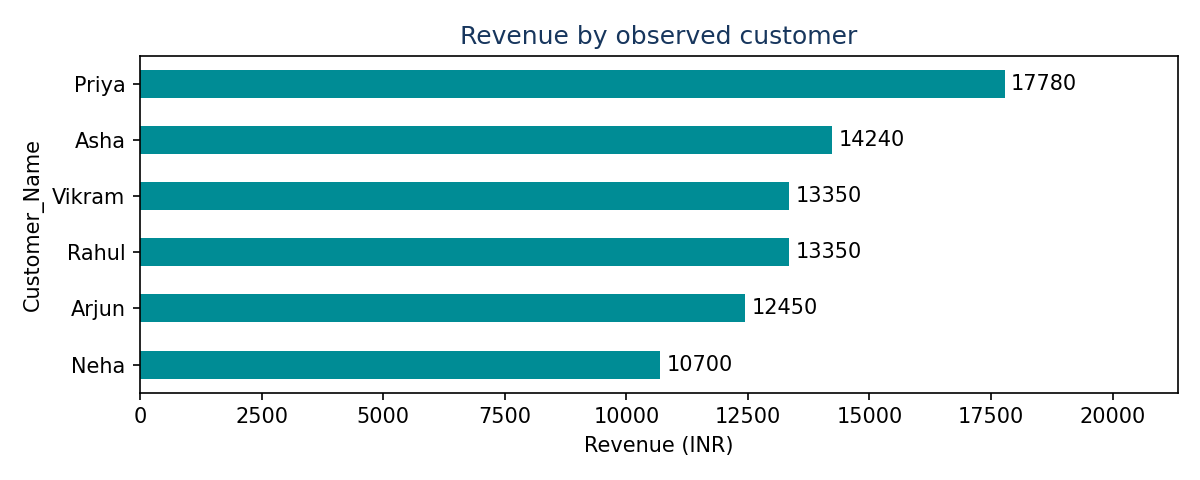

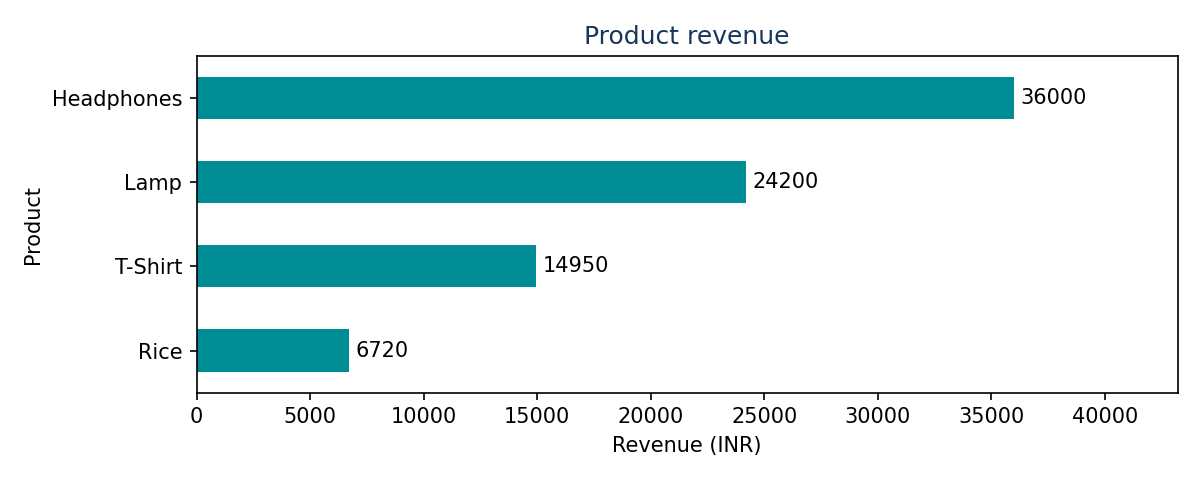

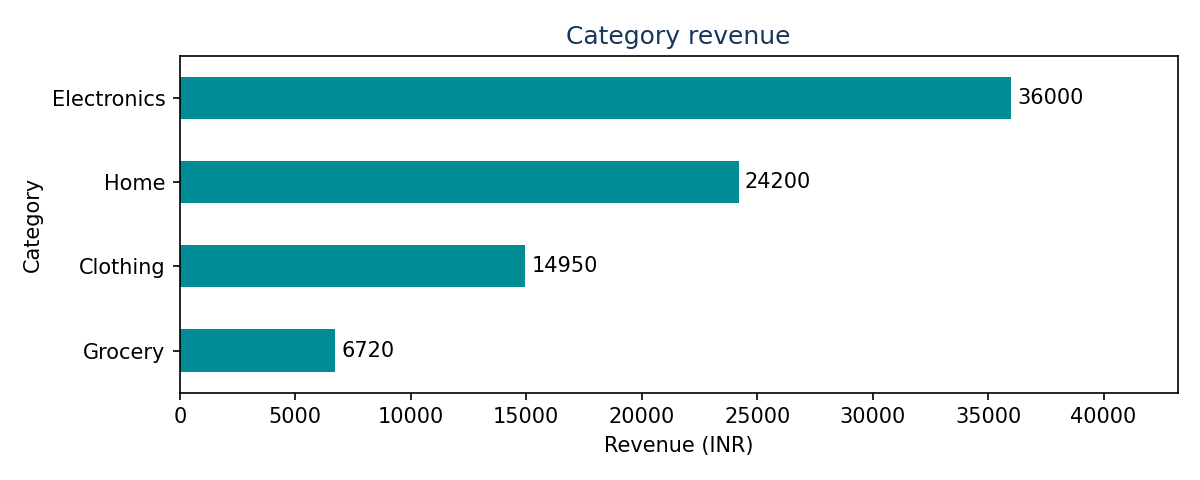

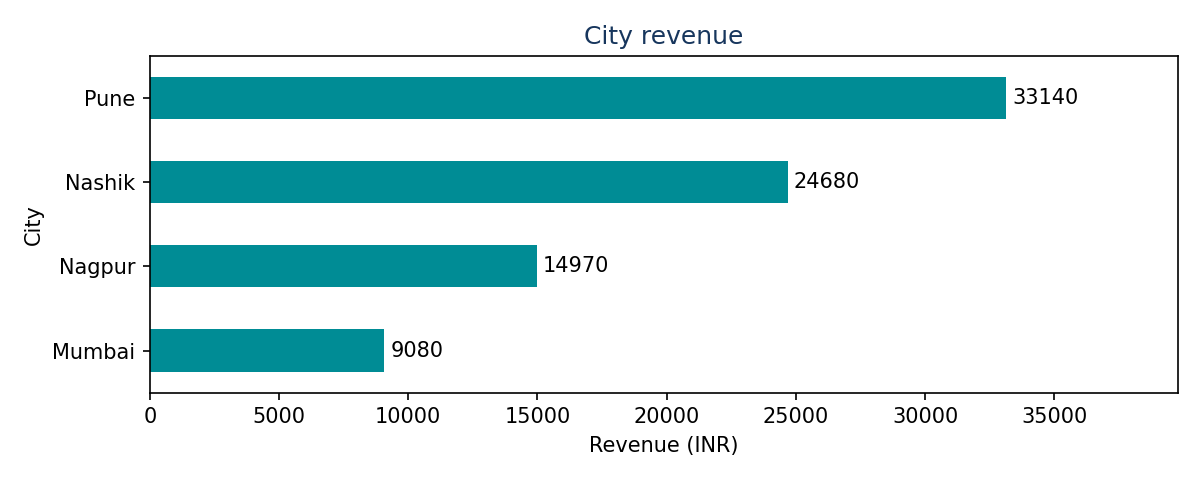

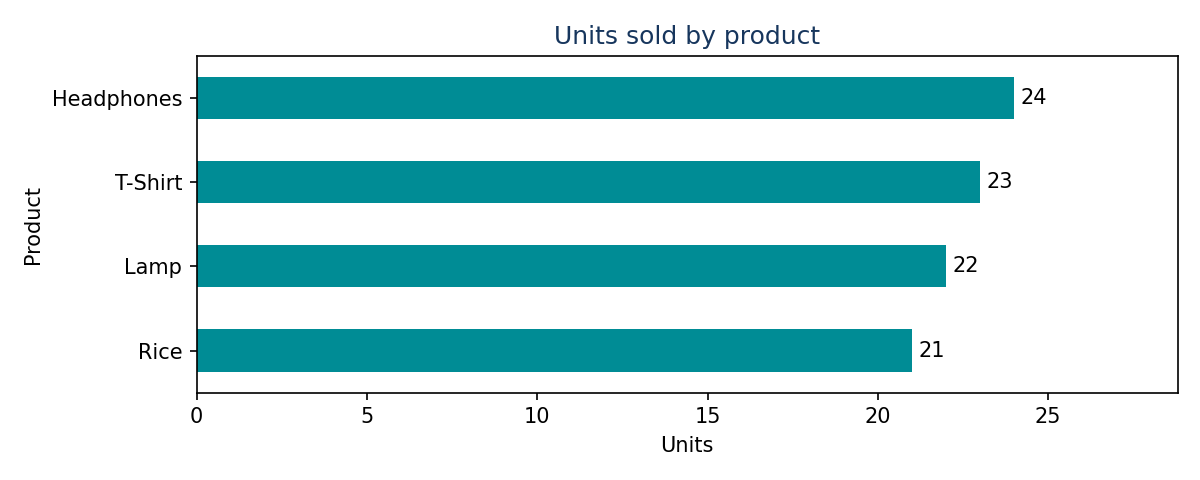

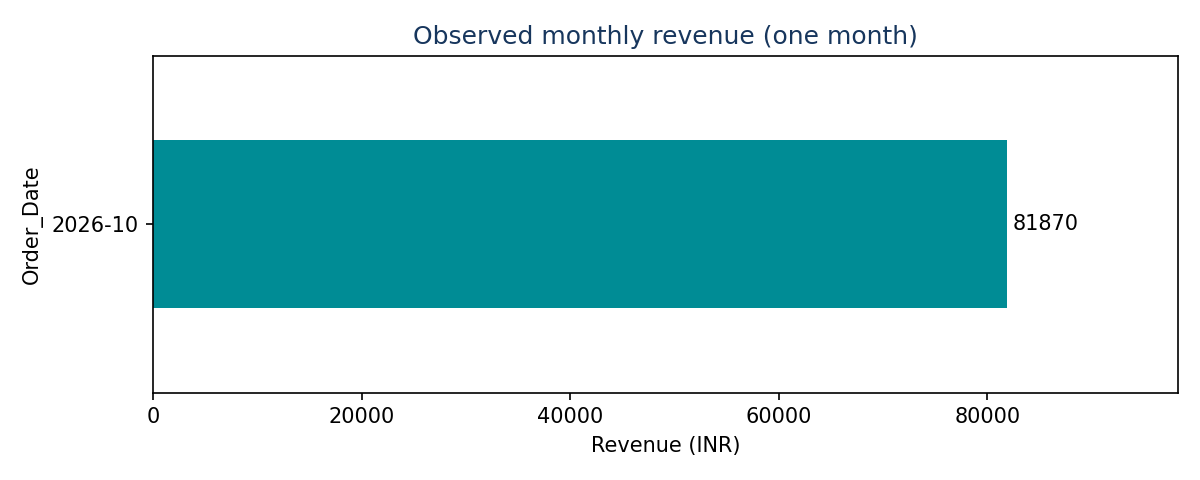

In [4]:
charts=Path('visualizations'); charts.mkdir(exist_ok=True)
for filename,series,title,xlabel in [('01_customer',customer.Revenue,'Revenue by observed customer','Revenue (INR)'),('02_product',product.Revenue,'Product revenue','Revenue (INR)'),('03_category',category,'Category revenue','Revenue (INR)'),('04_city',city,'City revenue','Revenue (INR)'),('05_units',product.Units,'Units sold by product','Units'),('06_month',monthly,'Observed monthly revenue (one month)','Revenue (INR)')]:
    fig,ax=plt.subplots(figsize=(8,3.2)); series.sort_values().plot.barh(ax=ax,color='#008C95'); ax.set_title(title,color='#17365D'); ax.set_xlabel(xlabel); ax.bar_label(ax.containers[0],fmt='%.0f',padding=3); ax.set_xlim(0,series.max()*1.2); fig.tight_layout(); path=charts/(filename+'.png'); fig.savefig(path,dpi=150); plt.close(fig); display(Image(filename=str(path)))


## Limitations
- Profit and profit margin: no usable profit/cost data; margin column is empty. No profitability rankings.
- Monthly trend: October 2026 only; no month-on-month growth or declining category claims.
- Customer identity: names are proxies, not verified unique customer IDs; repeat rate is within observed data.
- Region: city is the available geographic proxy. Small dataset and one product per category limit generalization.
- Day 28 remains pending.